# Vector geometry toolkit

Build and reshape `FeatureCollection`s:

- **`from_bbox`** / **`from_records`** — construct collections from a box or from dict rows.
- **`with_coordinates`** / **`with_centroid`** — attach x/y or centroid columns.
- **`explode`** — split multi-part geometries into single parts.
- **`concat`** — stack two collections.

## Setup

In [1]:
%matplotlib inline

import tempfile
from pathlib import Path

DATA = Path('../../../examples/data')
WORK = Path(tempfile.mkdtemp(prefix='pyramids-t3-'))
DATA.is_dir(), WORK.is_dir()

(True, True)

In [2]:
from shapely.geometry import Point

from pyramids.feature import FeatureCollection

## Construct — `from_bbox` and `from_records`

In [3]:
box = FeatureCollection.from_bbox((0.0, 0.0, 1.0, 1.0), epsg=4326)
pts = FeatureCollection.from_records(
    [{'id': 1, 'geometry': Point(0, 0)}, {'id': 2, 'geometry': Point(1, 1)}], crs=4326
)
(len(box), box.epsg), (len(pts), list(pts.columns))

((1, 4326), (2, ['id', 'geometry']))

## Derive columns — `with_coordinates` / `with_centroid`

In [4]:
polys = FeatureCollection.read_file(DATA / 'coello_polygons.geojson')
coords = polys.with_coordinates()
centroids = polys.with_centroid()
[c for c in coords.columns if c in ('x', 'y')], type(centroids).__name__

(['x', 'y'], 'FeatureCollection')

Plot the source polygons, then their centroids — the same features reduced to a single representative point each.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

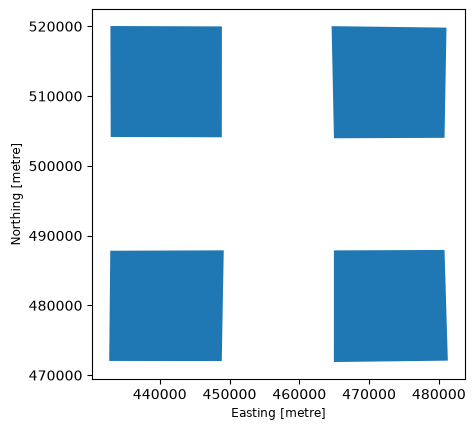

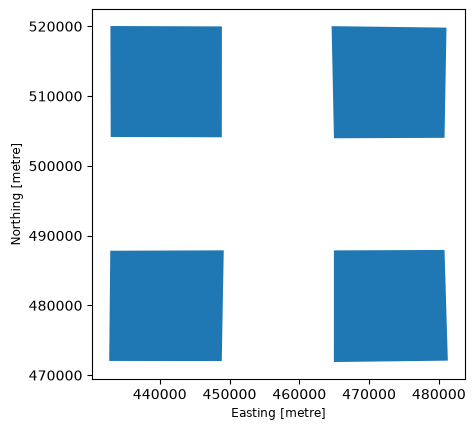

In [5]:
polys.plot()
centroids.plot()

## Reshape — `explode` and `concat`

In [6]:
single_parts = polys.explode()
stacked = polys.concat(polys)
(len(polys), '-> explode ->', len(single_parts)), ('concat ->', len(stacked))

/home/runner/work/pyramids-core/pyramids-core/.pixi/envs/docs/lib/python3.14/site-packages/pandas/core/generic.py:6448: FutureWarning: Overriding the CRS of a GeoDataFrame that already has CRS. This unsafe behavior will be deprecated in future versions. Use GeoDataFrame.set_crs method instead
  return object.__setattr__(self, name, value)


((4, '-> explode ->', 4), ('concat ->', 8))

Plot the exploded single-part geometries — each multi-part feature is now split into its own row.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

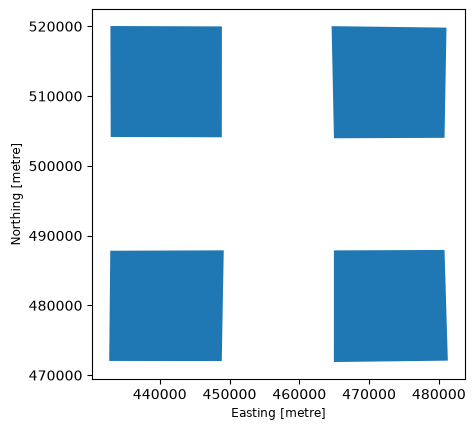

In [7]:
single_parts.plot()

## Notes

- A `FeatureCollection` is a `geopandas.GeoDataFrame` subclass, so all of geopandas works too.
- See also: [Rasterize ↔ vectorize](rasterize-vectorize.ipynb),
  [Vector formats](../conversions/vector-formats.ipynb).